# PR Context-Aware AI-Gen Profiler

This notebook wraps the Phase 3 profiler and produces:
- Risk score (`0.0` to `1.0`)
- Risk category (`LOW_RISK`, `UNVERIFIED`, `HIGH_AI_PROBABILITY`)
- Optional confusion matrix and classification report when a ground-truth label column is present

## 1) Imports and Path Setup
Run this cell first.

In [75]:
from pathlib import Path
import sys
import importlib
import pandas as pd

def find_repo_root(start: Path) -> Path:
    current = start.resolve()
    for candidate in [current] + list(current.parents):
        if (candidate / "phase3").exists():
            return candidate
    raise RuntimeError("Could not locate repository root containing phase3/")

REPO_ROOT = find_repo_root(Path.cwd())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import phase3.profiler.pr_context_aware_ai_gen_profiler as profiler_module
importlib.reload(profiler_module)
run_profiler = profiler_module.run_profiler

print(f"Repository root: {REPO_ROOT}")
print("Profiler module reloaded")

Repository root: /Users/ayo/Documents/ayo-workspace/iwadi/llm-in-prs
Profiler module reloaded


## 2) Configure Inputs
Required input columns in `INPUT_CSV`: `description_text`, `context_level`, `model_type`.

Optional ground-truth labels can be provided in `GROUND_TRUTH_COLUMN` (for example `label`).

In [76]:
INPUT_CSV = REPO_ROOT / "phase3/datasets/temperature_1/run_3/detection_results.csv"
OUTPUT_CSV = REPO_ROOT / "phase3/analysis/outputs/pr_context_aware_profiled_predictions.csv"
DETECTION_RESULTS_CSV = REPO_ROOT / "phase3/datasets/temperature_1/run_3/detection_results.csv"
RQ3_SUMMARY_DIR = REPO_ROOT / "phase3/analysis/outputs"

# Limit rows for interactive notebook runs. Set to None for full dataset.
MAX_ROWS = None

# Optional ground-truth column in the normalized input (e.g., label).
GROUND_TRUTH_COLUMN = "label"

# Default scoring path: local RoBERTa inference (open-source and low-cost).
# Set to a column like "zerogpt_ai_probability", "roberta-qa_ai_probability", "roberta_ai_probability", or "gptzero_ai_probability", only when you explicitly want precomputed detector scores.
PRECOMPUTED_PROBABILITY_COLUMN = 'roberta_ai_probability'

# Optional override for naive baseline comparison in Cell 15.
# Set to one of: None, "zerogpt", "roberta", "roberta-qa", "gptzero"
NAIVE_DETECTOR_OVERRIDE = 'zerogpt'

# Context ablation: hide context_level from the profiler by forcing a single label.
HIDE_CONTEXT = True
HIDDEN_CONTEXT_LABEL = "Unknown"

# Model ablation: hide model_type (generator LLM) from the profiler by forcing a single label.
HIDE_MODEL = True
HIDDEN_MODEL_LABEL = "Unknown-LLM"

DETECTOR_MODEL = "Hello-SimpleAI/chatgpt-detector-roberta"
DETECTOR_DEVICE = None  # "cpu" or "cuda"; None = auto
DETECTOR_BATCH_SIZE = 16  # Used when PRECOMPUTED_PROBABILITY_COLUMN is None

print(f"Input CSV: {INPUT_CSV}")
print(f"Output CSV: {OUTPUT_CSV}")
print(f"Max rows: {MAX_ROWS}")
print(f"Precomputed probability column: {PRECOMPUTED_PROBABILITY_COLUMN}")
print(f"Naive detector override: {NAIVE_DETECTOR_OVERRIDE}")
print(f"Hide context: {HIDE_CONTEXT} (label={HIDDEN_CONTEXT_LABEL})")
print(f"Hide model: {HIDE_MODEL} (label={HIDDEN_MODEL_LABEL})")
print(f"Detector model: {DETECTOR_MODEL}")
print(f"Detector batch size: {DETECTOR_BATCH_SIZE}")

Input CSV: /Users/ayo/Documents/ayo-workspace/iwadi/llm-in-prs/phase3/datasets/temperature_1/run_3/detection_results.csv
Output CSV: /Users/ayo/Documents/ayo-workspace/iwadi/llm-in-prs/phase3/analysis/outputs/pr_context_aware_profiled_predictions.csv
Max rows: None
Precomputed probability column: roberta_ai_probability
Naive detector override: zerogpt
Hide context: True (label=Unknown)
Hide model: True (label=Unknown-LLM)
Detector model: Hello-SimpleAI/chatgpt-detector-roberta
Detector batch size: 16


## 3) Run Profiling
Default behavior uses batched local RoBERTa scoring (`DETECTOR_MODEL`).

Optional alternative: set `PRECOMPUTED_PROBABILITY_COLUMN` to reuse existing detector outputs (for example `zerogpt_ai_probability`) when you want zero new detector calls.

Then it applies context/model weighting from RQ2 and GPT-5 stealth structural checks from RQ3 baselines.

In [77]:
raw_df = pd.read_csv(INPUT_CSV)

# Normalize common Phase 3 schemas to profiler-required columns.
if {"description_text", "context_level", "model_type"}.issubset(raw_df.columns):
    normalized_df = raw_df.copy()
elif {"text", "variation", "model"}.issubset(raw_df.columns):
    context_map = {
        "P-1": "Repo Path",
        "P-2": "PR Title",
        "P-3": "File Diff",
        "P-4": "File Contents",
        "P-5": "Linked Issue",
        "P-6": "Without File Contents",
    }
    normalized_df = pd.DataFrame(
        {
            "description_text": raw_df["text"].fillna("").astype(str),
            "context_level": raw_df["variation"].astype(str).map(context_map).fillna(raw_df["variation"].astype(str)),
            "model_type": raw_df["model"].fillna("unknown").astype(str),
            "label": raw_df.get("entry_type", pd.Series(["unknown"] * len(raw_df))).astype(str),
        }
    )
else:
    raise ValueError(
        "Input CSV must contain either [description_text, context_level, model_type] "
        "or [text, variation, model]."
    )

if PRECOMPUTED_PROBABILITY_COLUMN is not None:
    if PRECOMPUTED_PROBABILITY_COLUMN not in raw_df.columns:
        raise ValueError(f"Column not found in INPUT_CSV: {PRECOMPUTED_PROBABILITY_COLUMN}")
    normalized_df[PRECOMPUTED_PROBABILITY_COLUMN] = raw_df[PRECOMPUTED_PROBABILITY_COLUMN].values

if HIDE_CONTEXT:
    normalized_df["context_level"] = HIDDEN_CONTEXT_LABEL

if HIDE_MODEL:
    normalized_df["model_type"] = HIDDEN_MODEL_LABEL

normalized_df = normalized_df[normalized_df["description_text"].str.strip() != ""].copy()
if MAX_ROWS is not None:
    normalized_df = normalized_df.head(MAX_ROWS).copy()

prepared_input = OUTPUT_CSV.parent / "profiler_prepared_input.csv"
prepared_input.parent.mkdir(parents=True, exist_ok=True)
normalized_df.to_csv(prepared_input, index=False)

profiled_df = run_profiler(
    input_csv=prepared_input,
    output_csv=OUTPUT_CSV,
    detection_results_csv=DETECTION_RESULTS_CSV,
    rq3_summary_dir=RQ3_SUMMARY_DIR,
    ground_truth_column=GROUND_TRUTH_COLUMN,
    detector_model=DETECTOR_MODEL,
    detector_device=DETECTOR_DEVICE,
    detector_batch_size=DETECTOR_BATCH_SIZE,
    precomputed_probability_column=PRECOMPUTED_PROBABILITY_COLUMN,
 )

print(f"Prepared input saved to: {prepared_input}")
print(f"Saved predictions to: {OUTPUT_CSV}")
profiled_df.head(10)

Loading RoBERTa model: Hello-SimpleAI/chatgpt-detector-roberta on cpu...
RoBERTa model loaded successfully!
Prepared input saved to: /Users/ayo/Documents/ayo-workspace/iwadi/llm-in-prs/phase3/analysis/outputs/profiler_prepared_input.csv
Saved predictions to: /Users/ayo/Documents/ayo-workspace/iwadi/llm-in-prs/phase3/analysis/outputs/pr_context_aware_profiled_predictions.csv


,description_text,context_level,model_type,label,roberta_ai_probability,base_ai_probability,context_weight,model_weight,weighted_probability,word_count,...,lexical_density,ttr,mtld,fkgl,stealth_anomaly_score,stealth_flag,context_model_similarity_bonus,model_similarity_bonus,risk_score,risk_category
0,Fixes #9157: Added a new method `toUpperFirstI...,Unknown,Unknown-LLM,ai,NaN,0.500000,1.0,1.0,0.500000,25.0,...,0.920000,0.920000,87.500000,19.176000,0.189000,0,0.0,0.0,0.689000,HIGH_AI_PROBABILITY
1,Summary\n\nThis PR adds an option to automatic...,Unknown,Unknown-LLM,ai,0.000324,0.000324,1.0,1.0,0.000324,326.0,...,0.503067,0.503067,92.746629,9.721028,0.207000,0,0.0,0.0,0.207324,LOW_RISK
2,Summary\n\nRefactor and fix the Groups dialog ...,Unknown,Unknown-LLM,ai,0.000276,0.000276,1.0,1.0,0.000276,229.0,...,0.598253,0.598253,114.728088,13.535476,0.234738,0,0.0,0.0,0.235014,LOW_RISK
3,Make table column sort order persistent\n\nThi...,Unknown,Unknown-LLM,ai,0.000306,0.000306,1.0,1.0,0.000306,205.0,...,0.668293,0.668293,95.611559,20.448583,0.315713,0,0.0,0.0,0.316019,LOW_RISK
4,This pull request updates the CHANGELOG.md to ...,Unknown,Unknown-LLM,ai,0.066005,0.066005,1.0,1.0,0.066005,42.0,...,0.833333,0.833333,70.560000,12.620000,0.108000,0,0.0,0.0,0.174005,LOW_RISK
5,Catch and handle NumberFormatException when at...,Unknown,Unknown-LLM,ai,NaN,0.500000,1.0,1.0,0.500000,23.0,...,0.913043,0.913043,74.060000,16.466957,0.181696,0,0.0,0.0,0.681696,HIGH_AI_PROBABILITY
6,Adds drag and drop support for files in the Ge...,Unknown,Unknown-LLM,ai,0.151154,0.151154,1.0,1.0,0.151154,55.0,...,0.818182,0.818182,84.700000,9.804490,0.153000,0,0.0,0.0,0.304154,LOW_RISK
7,Fixes #8108 — show preview for available citat...,Unknown,Unknown-LLM,ai,0.000303,0.000303,1.0,1.0,0.000303,346.0,...,0.476879,0.476879,92.132954,14.069613,0.240949,0,0.0,0.0,0.241252,LOW_RISK
8,This pull request adds the ISSN field to the d...,Unknown,Unknown-LLM,ai,0.001007,0.001007,1.0,1.0,0.001007,56.0,...,0.785714,0.785714,73.173333,10.215741,0.143344,0,0.0,0.0,0.144351,LOW_RISK
9,This pull request introduces an additional che...,Unknown,Unknown-LLM,ai,0.000571,0.000571,1.0,1.0,0.000571,40.0,...,0.850000,0.850000,74.666667,15.810000,0.183306,0,0.0,0.0,0.183877,LOW_RISK


## 4) Quick Distribution Check
Review category counts and mean risk by context/model.

In [78]:
display(profiled_df["risk_category"].value_counts(dropna=False).to_frame("count"))

summary = (
    profiled_df.groupby(["context_level", "model_type"], dropna=False)["risk_score"]
    .agg(["count", "mean", "std"])
    .reset_index()
)
display(summary.sort_values(["context_level", "model_type"]))

,count
risk_category,
LOW_RISK,3604
UNVERIFIED,1240
HIGH_AI_PROBABILITY,992


,context_level,model_type,count,mean,std
0,Unknown,Unknown-LLM,5836,0.400688,0.303566


## 5) Load Evaluation Outputs (If Ground Truth Was Provided)
When `GROUND_TRUTH_COLUMN` is set and exists in the input, the profiler writes:
- `confusion_matrix.csv`
- `classification_report.csv`

In [79]:
cm_path = OUTPUT_CSV.parent / "confusion_matrix.csv"
cr_path = OUTPUT_CSV.parent / "classification_report.csv"

if cm_path.exists():
    print(f"Found: {cm_path}")
    display(pd.read_csv(cm_path, index_col=0))
else:
    print("No confusion matrix found. Set GROUND_TRUTH_COLUMN to evaluate predictions.")

if cr_path.exists():
    print(f"Found: {cr_path}")
    display(pd.read_csv(cr_path, index_col=0))
else:
    print("No classification report found. Set GROUND_TRUTH_COLUMN to evaluate predictions.")

Found: /Users/ayo/Documents/ayo-workspace/iwadi/llm-in-prs/phase3/analysis/outputs/confusion_matrix.csv


,pred_human,pred_ai
actual_human,263,45
actual_ai,3503,2025


Found: /Users/ayo/Documents/ayo-workspace/iwadi/llm-in-prs/phase3/analysis/outputs/classification_report.csv


,precision,recall,f1-score,support
human,0.069835,0.853896,0.129111,308.000000
ai,0.978261,0.366317,0.533035,5528.000000
accuracy,0.392049,0.392049,0.392049,0.392049
macro avg,0.524048,0.610107,0.331073,5836.000000
weighted avg,0.930318,0.392049,0.511718,5836.000000


## 6) Confusion Matrix Heatmap
Visual check for false positives and false negatives.

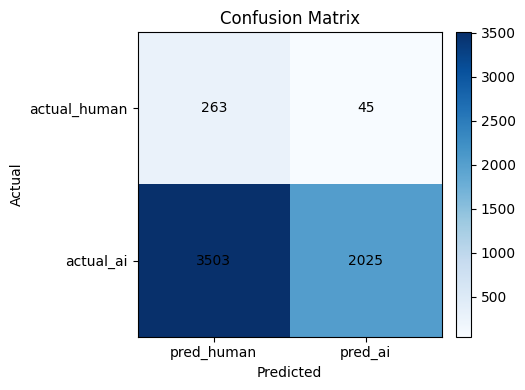

In [80]:
import numpy as np
import matplotlib.pyplot as plt

cm_path = OUTPUT_CSV.parent / "confusion_matrix.csv"

if cm_path.exists():
    cm_df = pd.read_csv(cm_path, index_col=0)
    matrix = cm_df.to_numpy(dtype=float)

    fig, ax = plt.subplots(figsize=(5, 4))
    im = ax.imshow(matrix, cmap="Blues")

    ax.set_xticks(np.arange(matrix.shape[1]))
    ax.set_yticks(np.arange(matrix.shape[0]))
    ax.set_xticklabels(cm_df.columns)
    ax.set_yticklabels(cm_df.index)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_title("Confusion Matrix")

    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            ax.text(j, i, int(matrix[i, j]), ha="center", va="center", color="black")

    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    plt.tight_layout()
    plt.show()
else:
    print("No confusion matrix available. Run profiling with GROUND_TRUTH_COLUMN set to generate it.")

## 7) Compare With Naive Detector Run
This section compares:
- naive run: direct detector decisions from the same run_3 detection file (auto-selected from current detector settings)
- profiler run: `risk_score >= 0.5`

It reports both:
- full-sample comparison
- overlap-only comparison (rows where naive has a valid detector decision and a direct match in profiler output).

In [81]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix

run_df = pd.read_csv(INPUT_CSV)
hide_context = bool(globals().get("HIDE_CONTEXT", False))
hide_model = bool(globals().get("HIDE_MODEL", False))
hidden_model_label = str(globals().get("HIDDEN_MODEL_LABEL", "Unknown-LLM"))

valid_naive_detectors = {"zerogpt", "roberta", "roberta-qa", "gptzero"}
override = globals().get("NAIVE_DETECTOR_OVERRIDE", None)
if override is not None:
    override = str(override).strip().lower()
    if override not in valid_naive_detectors:
        raise ValueError(
            f"Invalid NAIVE_DETECTOR_OVERRIDE={override}. "
            f"Use one of: {sorted(valid_naive_detectors)} or None"
        )

# Resolve which naive detector output to compare against.
naive_prefix = None
if override is not None:
    naive_prefix = override
elif PRECOMPUTED_PROBABILITY_COLUMN is not None and PRECOMPUTED_PROBABILITY_COLUMN.endswith("_ai_probability"):
    naive_prefix = PRECOMPUTED_PROBABILITY_COLUMN.replace("_ai_probability", "")
else:
    detector_model_l = str(DETECTOR_MODEL).lower()
    if "roberta-qa" in detector_model_l:
        naive_prefix = "roberta-qa"
    elif "roberta" in detector_model_l:
        naive_prefix = "roberta"
    elif "zerogpt" in detector_model_l:
        naive_prefix = "zerogpt"
    elif "gptzero" in detector_model_l:
        naive_prefix = "gptzero"
    else:
        naive_prefix = "roberta"

naive_is_ai_col = f"{naive_prefix}_is_ai"
if naive_is_ai_col not in run_df.columns:
    available = [c for c in run_df.columns if c.endswith("_is_ai")]
    raise ValueError(
        f"Naive detector column not found: {naive_is_ai_col}. "
        f"Available *_is_ai columns: {available}"
    )

print(f"Naive baseline detector: {naive_prefix}")
print(f"Hide context for overlap join: {hide_context}")
print(f"Hide model for overlap join: {hide_model} (label={hidden_model_label})")

# Build naive baseline from the same run file.
naive_df = run_df[run_df["text"].fillna("").astype(str).str.strip() != ""].copy()
naive_df = naive_df[naive_df["entry_type"].astype(str).str.lower().isin(["ai", "human"])].copy()
naive_df = naive_df[naive_df[naive_is_ai_col].notna()].copy()

y_true_naive = (naive_df["entry_type"].astype(str).str.lower() == "ai").astype(int)
y_pred_naive = naive_df[naive_is_ai_col].astype(str).str.lower().map({"true": 1, "false": 0})

acc_n = accuracy_score(y_true_naive, y_pred_naive)
p_n, r_n, f1_n, _ = precision_recall_fscore_support(y_true_naive, y_pred_naive, average="binary", zero_division=0)
cm_n = confusion_matrix(y_true_naive, y_pred_naive, labels=[0, 1])

# Profiler results from this notebook run.
prof_df = profiled_df[profiled_df["label"].astype(str).str.lower().isin(["ai", "human"])].copy()
y_true_prof = (prof_df["label"].astype(str).str.lower() == "ai").astype(int)
y_pred_prof = (prof_df["risk_score"] >= 0.5).astype(int)

acc_p = accuracy_score(y_true_prof, y_pred_prof)
p_p, r_p, f1_p, _ = precision_recall_fscore_support(y_true_prof, y_pred_prof, average="binary", zero_division=0)
cm_p = confusion_matrix(y_true_prof, y_pred_prof, labels=[0, 1])

comparison_full = pd.DataFrame([
    {"method": f"naive_{naive_prefix}", "n": len(naive_df), "accuracy": acc_n, "precision": p_n, "recall": r_n, "f1": f1_n},
    {"method": "profiler", "n": len(prof_df), "accuracy": acc_p, "precision": p_p, "recall": r_p, "f1": f1_p},
])

print("Full-sample comparison")
display(comparison_full)

print("Confusion matrices [TN, FP; FN, TP]")
print(f"naive_{naive_prefix}:")
print(cm_n)
print("profiler:")
print(cm_p)

# Overlap-only comparison for strict apples-to-apples rows.
context_map = {
    "P-1": "Repo Path",
    "P-2": "PR Title",
    "P-3": "File Diff",
    "P-4": "File Contents",
    "P-5": "Linked Issue",
    "P-6": "Without File Contents",
}

naive_keys = naive_df.copy()
naive_keys["description_text"] = naive_keys["text"].fillna("").astype(str)
naive_keys["context_level"] = naive_keys["variation"].astype(str).map(context_map).fillna(naive_keys["variation"].astype(str))
naive_keys["model_type"] = naive_keys["model"].fillna("unknown").astype(str)
if hide_model:
    naive_keys["model_type"] = hidden_model_label
naive_keys["label"] = naive_keys["entry_type"].astype(str).str.lower()
naive_keys["naive_pred"] = y_pred_naive.values

prof_keys = prof_df.copy()
prof_keys["label"] = prof_keys["label"].astype(str).str.lower()
if hide_model:
    prof_keys["model_type"] = hidden_model_label
prof_keys["prof_pred"] = y_pred_prof.values

if hide_context and hide_model:
    key_cols = ["description_text", "label"]
elif hide_context:
    key_cols = ["description_text", "model_type", "label"]
elif hide_model:
    key_cols = ["description_text", "context_level", "label"]
else:
    key_cols = ["description_text", "context_level", "model_type", "label"]

overlap = naive_keys[key_cols + ["naive_pred"]].merge(
    prof_keys[key_cols + ["prof_pred"]], on=key_cols, how="inner"
)

y_true_overlap = (overlap["label"] == "ai").astype(int)
acc_on = accuracy_score(y_true_overlap, overlap["naive_pred"])
p_on, r_on, f1_on, _ = precision_recall_fscore_support(y_true_overlap, overlap["naive_pred"], average="binary", zero_division=0)
acc_op = accuracy_score(y_true_overlap, overlap["prof_pred"])
p_op, r_op, f1_op, _ = precision_recall_fscore_support(y_true_overlap, overlap["prof_pred"], average="binary", zero_division=0)

comparison_overlap = pd.DataFrame([
    {"method": f"naive_{naive_prefix}_overlap", "n": len(overlap), "accuracy": acc_on, "precision": p_on, "recall": r_on, "f1": f1_on},
    {"method": "profiler_overlap", "n": len(overlap), "accuracy": acc_op, "precision": p_op, "recall": r_op, "f1": f1_op},
])

print("Overlap-only comparison")
display(comparison_overlap)

delta = pd.DataFrame([{
    "delta_accuracy": acc_op - acc_on,
    "delta_precision": p_op - p_on,
    "delta_recall": r_op - r_on,
    "delta_f1": f1_op - f1_on,
}])
print("Profiler - Naive delta on overlap")
display(delta)

Naive baseline detector: zerogpt
Hide context for overlap join: True
Hide model for overlap join: True (label=Unknown-LLM)
Full-sample comparison


,method,n,accuracy,precision,recall,f1
0,naive_zerogpt,5836,0.226525,1.000000,0.183430,0.309997
1,profiler,5836,0.392049,0.978261,0.366317,0.533035


Confusion matrices [TN, FP; FN, TP]
naive_zerogpt:
[[ 308    0]
 [4514 1014]]
profiler:
[[ 263   45]
 [3503 2025]]
Overlap-only comparison


,method,n,accuracy,precision,recall,f1
0,naive_zerogpt_overlap,5838,0.226790,1.000000,0.183725,0.310419
1,profiler_overlap,5838,0.391915,0.978261,0.366184,0.532895


Profiler - Naive delta on overlap


,delta_accuracy,delta_precision,delta_recall,delta_f1
0,0.165125,-0.021739,0.182459,0.222476


## 8) Metric Delta Chart
Bar chart of profiler minus naive performance on the overlap-only comparison.

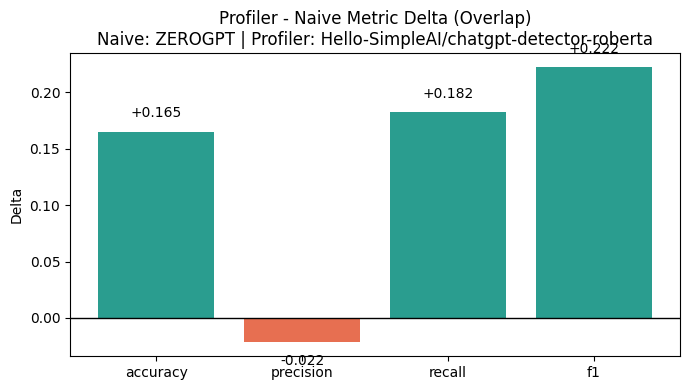

In [82]:
import matplotlib.pyplot as plt

# Recompute deltas directly from overlap comparison values.
metrics = ["accuracy", "precision", "recall", "f1"]
delta_values = [
    acc_op - acc_on,
    p_op - p_on,
    r_op - r_on,
    f1_op - f1_on,
]

naive_detector_name = str(globals().get("naive_prefix", "unknown")).upper()
profiler_detector_name = str(globals().get("DETECTOR_MODEL", "unknown"))

colors = ["#2a9d8f" if v >= 0 else "#e76f51" for v in delta_values]

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(metrics, delta_values, color=colors)
ax.axhline(0, color="black", linewidth=1)
ax.set_title(
    f"Profiler - Naive Metric Delta (Overlap)\n"
    f"Naive: {naive_detector_name} | Profiler: {profiler_detector_name}"
)
ax.set_ylabel("Delta")

for bar, value in zip(bars, delta_values):
    y = value + 0.01 if value >= 0 else value - 0.01
    va = "bottom" if value >= 0 else "top"
    ax.text(bar.get_x() + bar.get_width() / 2, y, f"{value:+.3f}", ha="center", va=va)

plt.tight_layout()
plt.show()